# Laboratorium 3 — Prognozowanie szeregów czasowych

**Cel:** zbudować model GRU prognozujący dzienną sprzedaż i porównać go z baseline'ami
(naiwny, sezonowy, średnia ruchoma). Nacisk na **poprawną walidację czasową** (bez przecieku danych).

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [1]:
!pip -q install torch numpy matplotlib

In [2]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'; print('Urządzenie:', DEVICE)

Urządzenie: cpu


## 2. Dane: dzienna sprzedaż

Szereg syntetyczny: trend + sezonowość tygodniowa (7) i roczna (365) + szum.
Podmień na własne dane biznesowe (pandas: `df['sprzedaz'].values`).

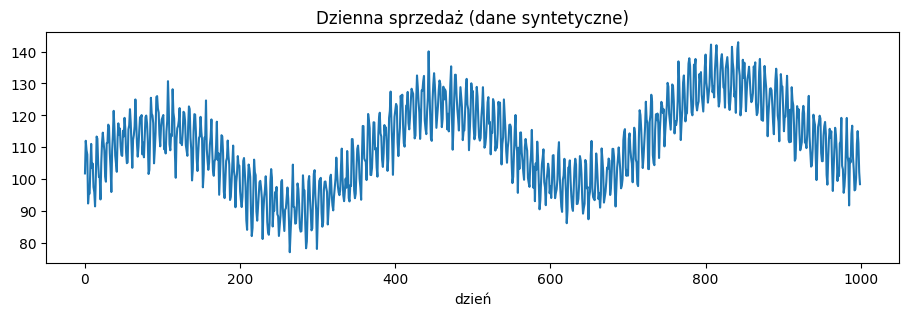

In [43]:
def generuj_sprzedaz(n=1000):
    t = np.arange(n)
    trend = 0.02*t
    tygodniowa = 8*np.sin(2*np.pi*t/7)
    roczna = 15*np.sin(2*np.pi*t/365)
    szum = np.random.randn(n)*3
    return (100 + trend + tygodniowa + roczna + szum).astype(np.float32)

seria_z1 = generuj_sprzedaz(1000)
plt.figure(figsize=(11,3)); plt.plot(seria_z1)
plt.title('Dzienna sprzedaż (dane syntetyczne)'); plt.xlabel('dzień'); plt.show()

## Wczytanie własnych danych
Publiczny zbiór danych o ruchu rowerowym (Fremont Bridge, Seattle), ograniczony do 1000 pierwszych dni.

/tmp/ipykernel_2845/923589817.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'])


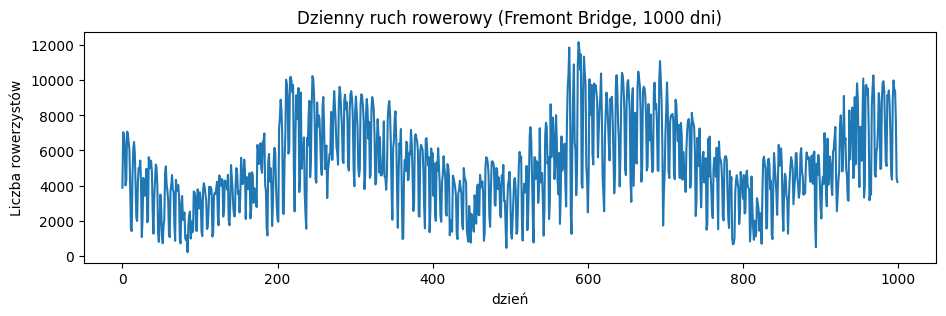

In [44]:
import pandas as pd
# dane ruchu rowerowym na moście Fremont w Seattle
url = "https://data.seattle.gov/api/views/65db-xm6k/rows.csv?accessType=DOWNLOAD"
df = pd.read_csv(url)
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')
seria_dzienna = df.select_dtypes(include='number').sum(axis=1).resample('D').sum()
seria = seria_dzienna.values[:1000].astype(np.float32)

plt.figure(figsize=(11,3))
plt.plot(seria)
plt.title('Dzienny ruch rowerowy (Fremont Bridge, 1000 dni)')
plt.xlabel('dzień')
plt.ylabel('Liczba rowerzystów')
plt.show()

## 3. Podział chronologiczny i standaryzacja (bez przecieku)


In [45]:
n=len(seria); i_tr=int(0.7*n); i_va=int(0.85*n)
mu, sd = seria[:i_tr].mean(), seria[:i_tr].std()
s = (seria - mu) / sd    # standaryzacja na statystykach treningu
print(f'Trening: 0..{i_tr}  Walidacja: {i_tr}..{i_va}  Test: {i_va}..{n}')

Trening: 0..700  Walidacja: 700..850  Test: 850..1000


## 4. Okna wejście–cel


In [46]:
OKNO = 28
def zrob_okna(s, okno, i_lo, i_hi):
    X, Y = [], []
    for i in range(max(okno, i_lo), i_hi):
        X.append(s[i-okno:i]); Y.append(s[i])
    return np.array(X,np.float32)[...,None], np.array(Y,np.float32)[:,None]

Xtr,Ytr = zrob_okna(s, OKNO, OKNO, i_tr)
Xva,Yva = zrob_okna(s, OKNO, i_tr, i_va)
Xte,Yte = zrob_okna(s, OKNO, i_va, n)
to_t = lambda a: torch.tensor(a).to(DEVICE)
Xtr,Ytr,Xva,Yva,Xte,Yte = map(to_t, [Xtr,Ytr,Xva,Yva,Xte,Yte])
print('kształty:', Xtr.shape, Xva.shape, Xte.shape)

kształty: torch.Size([672, 28, 1]) torch.Size([150, 28, 1]) torch.Size([150, 28, 1])


## 5. Model GRU i uczenie


najlepsza epoka: 36


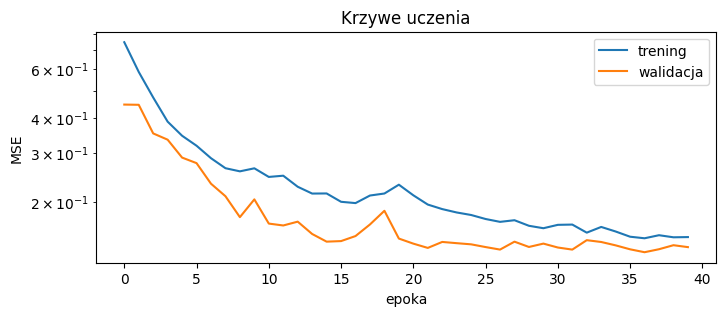

In [47]:
class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x); return self.fc(out[:, -1, :])

def trenuj(model, epoki=40, lr=1e-2, batch=64, dane=None):
    Xtr_, Ytr_, Xva_, Yva_ = dane if dane is not None else (Xtr, Ytr, Xva, Yva)
    model=model.to(DEVICE); opt=torch.optim.Adam(model.parameters(), lr=lr); L=nn.MSELoss()
    best=1e9; best_state=None; best_ep=0; h_tr=[]; h_va=[]
    for ep in range(epoki):
        model.train(); perm = torch.randperm(len(Xtr_)); straty = []
        for i in range(0, len(Xtr_), batch):
            idx = perm[i:i+batch]; opt.zero_grad()
            loss = L(model(Xtr_[idx]), Ytr_[idx]); loss.backward()
            opt.step(); straty.append(loss.item())
        model.eval()
        with torch.no_grad(): v = L(model(Xva_), Yva_).item()
        h_tr.append(np.mean(straty)); h_va.append(v)
        if v<best:
            best, best_ep = v, ep
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, h_tr, h_va, best_ep

torch.manual_seed(0)
model, h_tr, h_va, best_ep = trenuj(ModelGRU(32))
print(f'najlepsza epoka: {best_ep}')

plt.figure(figsize=(8,3))
plt.plot(h_tr, label='trening'); plt.plot(h_va, label='walidacja')
plt.yscale('log'); plt.xlabel('epoka'); plt.ylabel('MSE')
plt.title('Krzywe uczenia'); plt.legend(); plt.show()

## 6. Predykcja na teście (w oryginalnej skali)

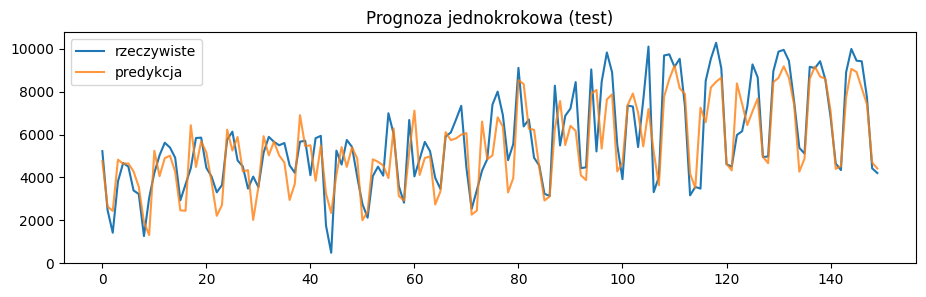

In [48]:
model.eval()
with torch.no_grad(): pred = model(Xte).cpu().numpy().ravel()
pred_raw = pred*sd + mu
true_raw = Yte.cpu().numpy().ravel()*sd + mu

plt.figure(figsize=(11,3))
plt.plot(true_raw, label='rzeczywiste')
plt.plot(pred_raw, label='predykcja', alpha=0.8)
plt.legend(); plt.title('Prognoza jednokrokowa (test)'); plt.show()

## 7. Porównanie z baseline'ami

In [49]:
def mae(a,b): return float(np.mean(np.abs(a-b)))
def rmse(a,b): return float(np.sqrt(np.mean((a-b)**2)))

tgt = np.arange(i_va, n)
naive    = seria[tgt-1]
seasonal = seria[tgt-7]
ma = np.array([seria[i-OKNO:i].mean() for i in tgt], np.float32)

print(f'{"metoda":16s}  MAE    RMSE')
print(f'{"RNN (GRU)":16s} {mae(true_raw,pred_raw):5.2f}  {rmse(true_raw,pred_raw):5.2f}')
print(f'{"naiwny (t-1)":16s} {mae(true_raw,naive):5.2f}  {rmse(true_raw,naive):5.2f}')
print(f'{"sezonowy (t-7)":16s} {mae(true_raw,seasonal):5.2f}  {rmse(true_raw,seasonal):5.2f}')
print(f'{"śr. ruchoma":16s} {mae(true_raw,ma):5.2f}  {rmse(true_raw,ma):5.2f}')

metoda            MAE    RMSE
RNN (GRU)        950.05  1223.08
naiwny (t-1)     1475.12  2018.32
sezonowy (t-7)   1283.77  1648.08
śr. ruchoma      1561.54  1874.52


## 8. Prognoza wielokrokowa (rekurencyjna)


liczba startów: 10
metoda     MAE    RMSE   (H = 14)
GRU        1239.83  1531.56
sezonowy   1331.20  1710.99
naiwny     1936.46  2549.14


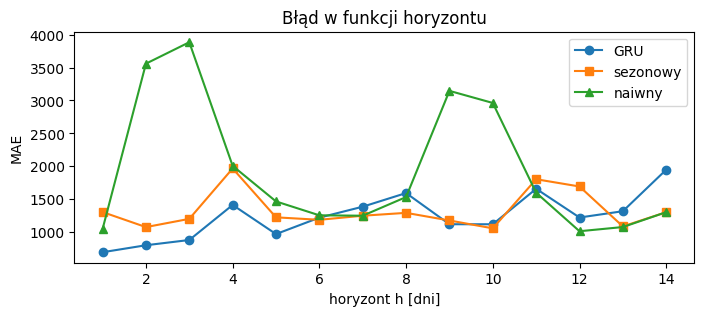

In [50]:
def prognoza(model, t0, H=14, okno_len=OKNO):
    okno = s[t0-okno_len:t0].tolist()
    preds = []
    model.eval()
    for _ in range(H):
        x = torch.tensor(np.array(okno[-okno_len:], np.float32).reshape(1, okno_len, 1)).to(DEVICE)
        with torch.no_grad(): nx = model(x).item()
        preds.append(nx)
        okno.append(nx)
    return np.array(preds) * sd + mu

def ocena_wielokrokowa(model, H=14, okno_len=OKNO):
    bledy = {'GRU': [], 'sezonowy': [], 'naiwny': []}
    for t0 in range(i_va, n - H + 1, H):
        prawda = seria[t0:t0+H]
        prognozy = {
            'GRU': prognoza(model, t0, H, okno_len),
            'sezonowy': np.array([seria[t0 - 7 + (h % 7)] for h in range(H)]),
            'naiwny': np.full(H, seria[t0-1])
        }
        for k, p in prognozy.items(): bledy[k].append(p - prawda)
    return {k: np.array(v) for k, v in bledy.items()}

H = 14
bledy = ocena_wielokrokowa(model, H, OKNO)

print(f'liczba startów: {len(bledy["GRU"])}')
print(f'{"metoda":10s} MAE    RMSE   (H = {H})')
for k, e in bledy.items():
    print(f'{k:10s} {np.abs(e).mean():5.2f}  {np.sqrt((e**2).mean()):5.2f}')

plt.figure(figsize=(8,3))
for k, znak in [('GRU', 'o-'), ('sezonowy', 's-'), ('naiwny', '^-')]:
    plt.plot(range(1, H+1), np.abs(bledy[k]).mean(axis=0), znak, label=k)
plt.xlabel('horyzont h [dni]'); plt.ylabel('MAE')
plt.title('Błąd w funkcji horyzontu')
plt.legend(); plt.show()

## Wpływ długości okna

In [51]:
def eksperyment(okno, ziarno, epoki=40):
    Xtr_np, Ytr_np = zrob_okna(s, okno, okno, i_tr)
    Xva_np, Yva_np = zrob_okna(s, okno, i_tr, i_va)
    Xte_np, Yte_np = zrob_okna(s, okno, i_va, n)
    to_t = lambda a: torch.tensor(a).to(DEVICE)
    Xtr_, Ytr_, Xva_, Yva_, Xte_, Yte_ = map(to_t, [Xtr_np, Ytr_np, Xva_np, Yva_np, Xte_np, Yte_np])
    dane = (Xtr_, Ytr_, Xva_, Yva_)
    torch.manual_seed(ziarno)
    m, _, h_va_, b_ep = trenuj(ModelGRU(32), epoki=epoki, dane=dane)
    m.eval()
    with torch.no_grad():
        p = m(Xte_).cpu().numpy().ravel() * sd + mu
    y = Yte_.cpu().numpy().ravel() * sd + mu
    e = ocena_wielokrokowa(m, H=14, okno_len=okno)['GRU']
    return min(h_va_), mae(y, p), float(np.abs(e).mean())

okna, ziarna = [3, 7, 28], [0, 1]
print(f'{"okno":>4s} {"ziarno":>6s} {"val MSE":>8s} {"MAE 1-krok":>11s} {"MAE 14-krok":>12s}')
wyniki = {}
for o in okna:
    for z in ziarna:
        wyniki[(o, z)] = eksperyment(o, z)
        v, m1, mH = wyniki[(o, z)]
        print(f'{o:4d} {z:6d} {v:8.4f} {m1:11.2f} {mH:12.2f}')

najlepsze = min(okna, key=lambda o: np.mean([wyniki[(o, z)][0] for z in ziarna]))
print('Najlepsze okno według walidacji:', najlepsze)

okno ziarno  val MSE  MAE 1-krok  MAE 14-krok
   3      0   0.3140     1239.01      2464.66
   3      1   0.3091     1262.89      2631.93
   7      0   0.1637     1022.89      1342.55
   7      1   0.1745      987.49      1269.97
  28      0   0.1319      950.05      1239.83
  28      1   0.1346      980.65      1240.46
Najlepsze okno według walidacji: 28
